# 第094讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Working directory:', pathlib.Path.cwd())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Working directory: [build path redacted]


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "probe": {
    "random": {
      "linear_probe_accuracy": 0.9549999833106995,
      "feature_std_mean": 0.0026371809653937817
    },
    "contrastive": {
      "linear_probe_accuracy": 1.0,
      "feature_std_mean": 0.03371661528944969
    }
  },
  "initial_loss": 5.540591239929199,
  "final_loss": 3.3189034461975098,
  "collapsed_loss_16_views": 2.708050012588501,
  "collapsed_expected_log15": 2.70805020110221,
  "unlabeled_updates": 180,
  "probe_updates": 150,
  "seconds": 2.561334640000041,
  "environment": {
    "python": "3.12.14",
    "torch": "2.14.1+cpu",
    "numpy": "2.3.5",
    "device": "cpu",
    "threads": 1
  }
}

Script exit: 0


In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_collapsed_loss (test_experiment.TestMechanism.test_collapsed_loss) ... ok
test_correct_pairs_better (test_experiment.TestMechanism.test_correct_pairs_better) ... ok
test_finite_backward (test_experiment.TestMechanism.test_finite_backward) ... ok
test_pair_permutation (test_experiment.TestMechanism.test_pair_permutation) ... ok
test_probe_does_not_mutate_encoder (test_experiment.TestMechanism.test_probe_does_not_mutate_encoder) ... ok
test_temperature_validation (test_experiment.TestMechanism.test_temperature_validation) ... ok

----------------------------------------------------------------------
Ran 6 tests in 1.123s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['probe', 'initial_loss', 'final_loss', 'collapsed_loss_16_views', 'collapsed_expected_log15', 'unlabeled_updates', 'probe_updates', 'seconds', 'environment']


01_contrastive.png
02_features.png
03_mechanism.png


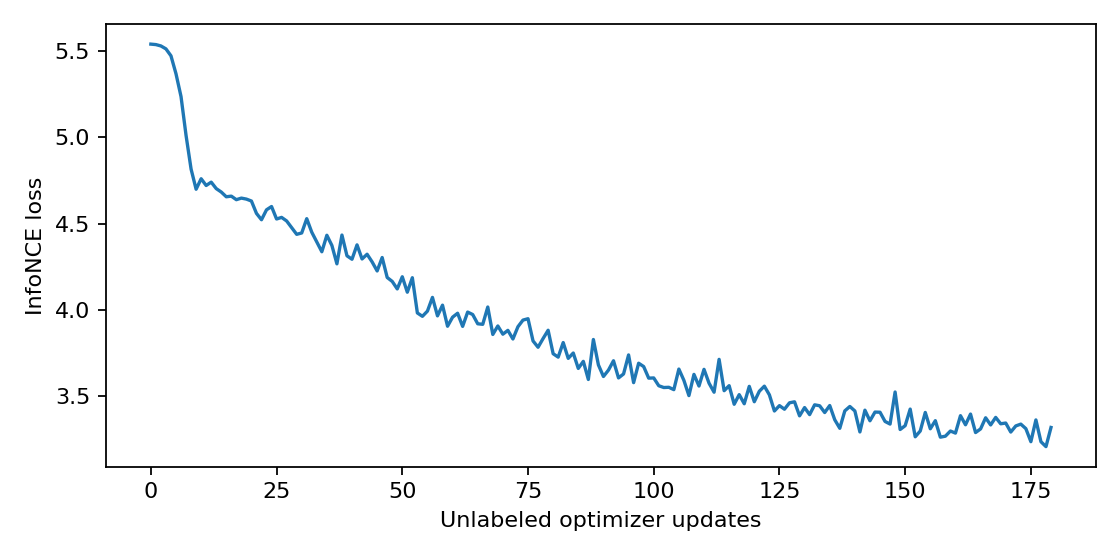

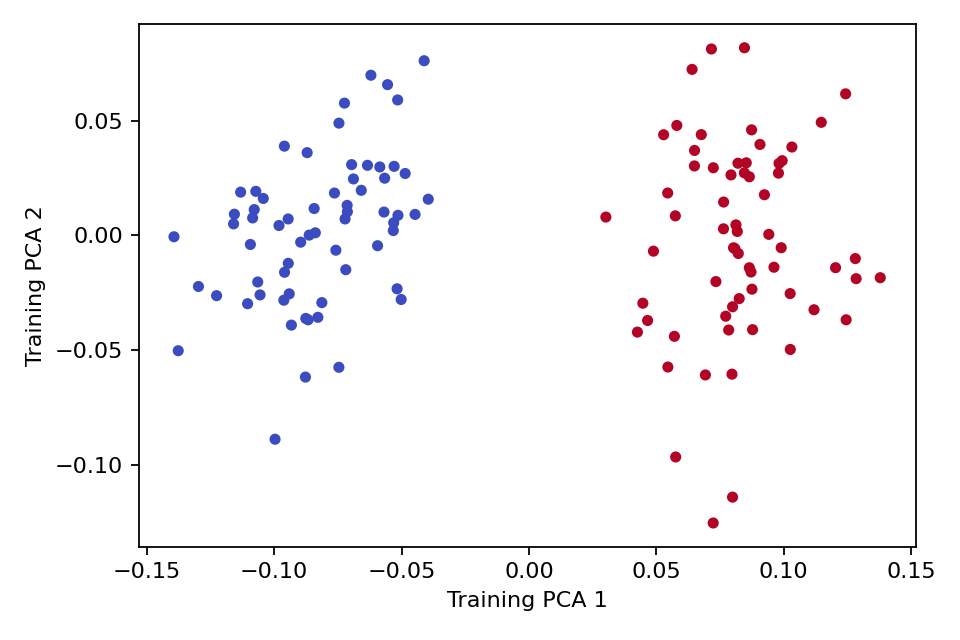

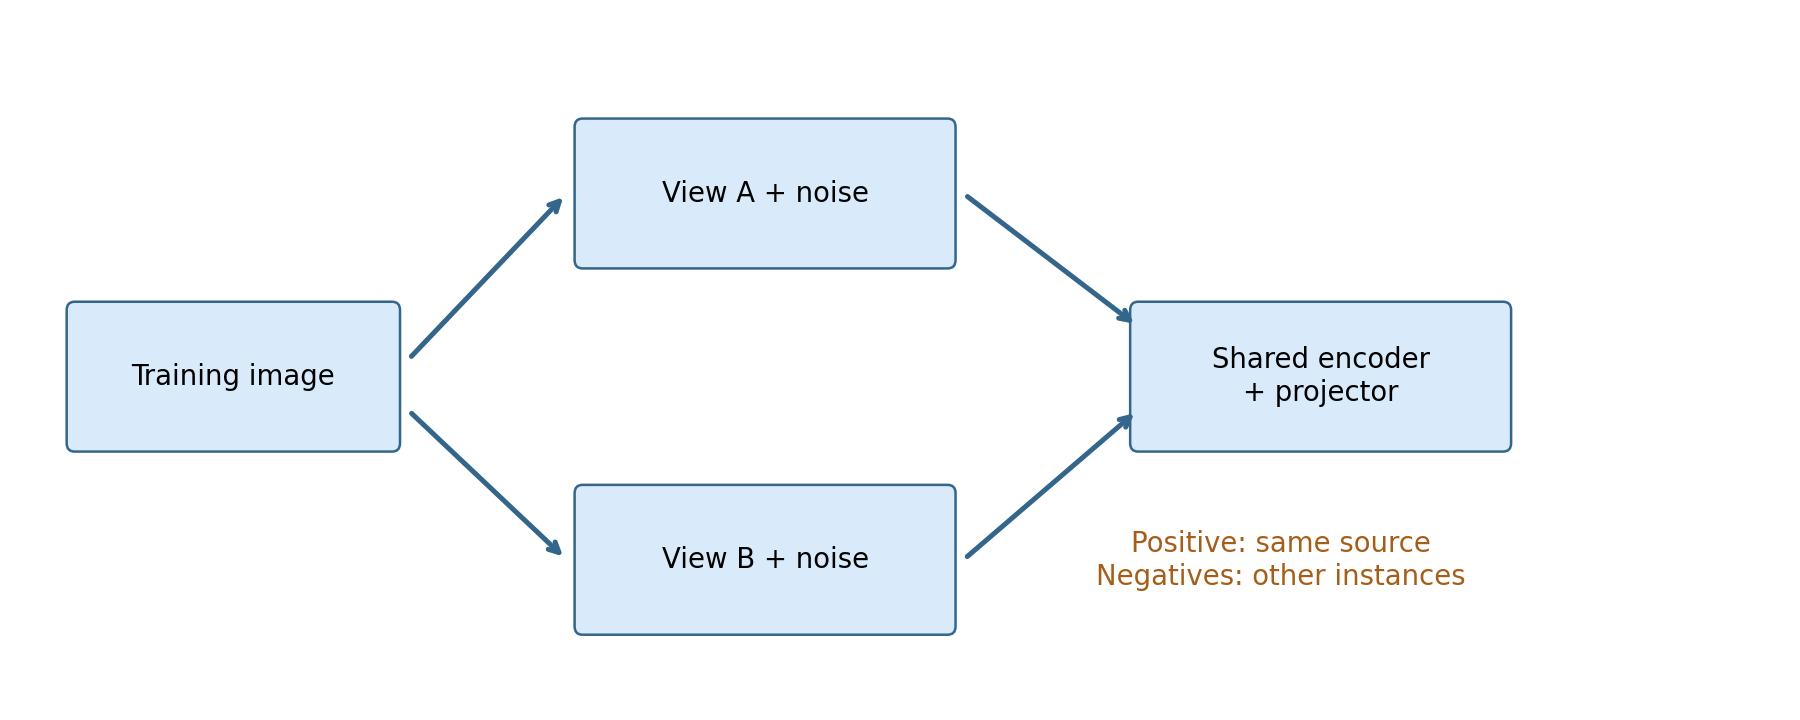

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。